# 4. Word2Vec (skip-gram + negative sampling) tự cài bằng NumPy

Mikolov et al. (2013), không dùng gensim (`BE/apps/algorithms/word2vec.py`). Huấn luyện trên câu tiếng Anh của
Tatoeba; mỗi khái niệm từ vựng nhận vector của từ tiếng Anh tương ứng, nên cùng một không gian nghĩa dùng chung cho
khoá tiếng Anh, tiếng Trung và tiếng Việt. Vector được Smart Distractor (notebook 5) dùng để chọn đáp án nhiễu.

`L = −log σ(u_o · v_c) − Σₖ log σ(−u_nₖ · v_c)`, nₖ ~ U(w)^0,75; SGD theo mini-batch, tốc độ học giảm tuyến tính,
lấy mẫu thưa từ phổ biến với p_keep = (√(f/t) + 1)·t/f.

> **Cách chạy:** mở bằng VS Code (hoặc Jupyter), chọn kernel **LingoPrism (BE venv)** rồi *Run All*. PostgreSQL phải đang chạy. Notebook dùng đúng mã nguồn của server (`BE/apps/algorithms`), kết quả được lưu vào database nên trang **Admin → Thuật toán AI** hiện ngay kết quả mới nhất. Mọi biểu đồ được lưu thêm thành ảnh PNG trong `AI/notebooks/figures/` để đưa vào báo cáo.

In [1]:
# Khởi tạo: nạp Django của BE/ (database + mã thuật toán thật của server) và matplotlib
import pathlib, sys
_here = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "AI/notebooks/lingoprism_setup.py").exists())
sys.path.insert(0, str(_here / "AI/notebooks"))
from lingoprism_setup import ROOT, init, save, table
init()

import random, time
import numpy as np
import matplotlib.pyplot as plt

Django OK – config.settings.dev | hình lưu ở D:\kicuoi\doantotnghiep\SnapLingua-main\AI\notebooks\figures


## 4.1 Tham số
Model đang dùng được train với 2 000 000 câu × 5 epoch × 100 chiều (~20 phút). Để chạy thử nhanh dùng 300 000 câu.
`SAVE_VECTORS = True` sẽ **ghi đè** vector đang dùng của hệ thống.

In [2]:
SENTENCES = 300_000
EPOCHS = 3
DIM = 100
WINDOW = 4
NEGATIVE = 5
SAVE_VECTORS = False

In [3]:
from apps.algorithms import word2vec
from apps.vocab.management.commands import import_tatoeba as tat

rows = [r[2] for r in tat._rows("eng_sentences_detailed.tsv.bz2") if len(r) >= 3]
pick = np.random.default_rng(0).choice(len(rows), size=min(SENTENCES, len(rows)), replace=False)
corpus = [word2vec.tokenize(rows[i]) for i in pick]
del rows
print(f"{len(corpus):,} câu, {sum(map(len, corpus)):,} từ")
print("ví dụ:", corpus[:3])

300,000 câu, 2,323,103 từ
ví dụ: [['i', 'like', 'your', 'village'], ['i', 'injured', 'my', 'knee', 'the', 'day', 'before', 'yesterday', 'and', 'it', 'still', 'hurts'], ['edmundo', 'heard', 'several', 'rumors', 'about', 'what', 'the', 'lockdown', 'was', 'for']]


## 4.2 Huấn luyện

  epoch 1/3: 5,390,487 cặp, loss 2.595, 41s


  epoch 2/3: 5,388,991 cặp, loss 2.333, 81s


  epoch 3/3: 5,387,734 cặp, loss 2.276, 118s
Từ điển 13,186 từ – 119s


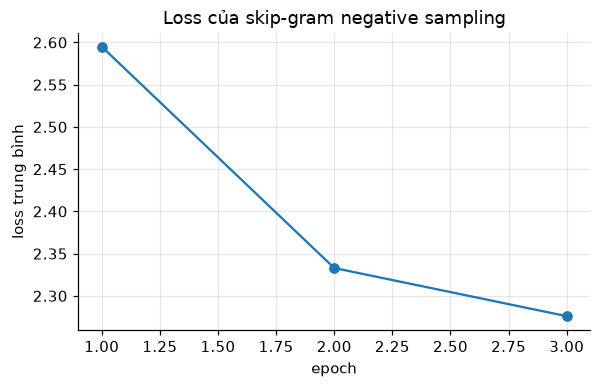

In [4]:
import re
losses = []
def log(msg):
    print(msg)
    m = re.search(r"loss ([\d.]+)", msg)
    if m:
        losses.append(float(m.group(1)))

t0 = time.time()
index, vecs = word2vec.train(corpus, dim=DIM, window=WINDOW, negative=NEGATIVE, epochs=EPOCHS, log=log)
duration = time.time() - t0
print(f"Từ điển {len(index):,} từ – {duration:.0f}s")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, len(losses) + 1), losses, marker="o")
ax.set_xlabel("epoch")
ax.set_ylabel("loss trung bình")
ax.set_title("Loss của skip-gram negative sampling")
save(fig, "04_w2v_loss")
plt.show()

## 4.3 Kiểm tra: các từ gần nghĩa nhất (cosine)

In [5]:
unit = vecs / np.maximum(np.linalg.norm(vecs, axis=1, keepdims=True), 1e-9)
words = list(index)
for q in ["cat", "apple", "teacher", "bus", "red", "happy", "rain", "doctor", "kitchen", "monday"]:
    if q in index:
        sims = unit @ unit[index[q]]
        nn = [f"{words[i]} ({sims[i]:.2f})" for i in np.argsort(-sims)[1:7]]
        print(f"{q:8s} → {', '.join(nn)}")

cat      → dog (0.75), knee (0.72), mouse (0.72), snake (0.69), puppy (0.68), cookie (0.68)
apple    → orange (0.80), banana (0.78), egg (0.77), iced (0.77), pie (0.76), lemon (0.73)
teacher  → coach (0.70), doctor (0.67), manager (0.67), textbook (0.66), speaker (0.66), boss (0.65)
bus      → train (0.85), subway (0.78), taxi (0.76), airport (0.75), plane (0.73), station (0.71)
red      → yellow (0.87), blue (0.85), black (0.82), green (0.81), purple (0.79), grey (0.79)
happy    → pleased (0.76), miserable (0.75), unhappy (0.75), thrilled (0.74), grateful (0.74), disappointed (0.71)
rain     → snow (0.76), rains (0.73), cloudy (0.72), sunny (0.71), raining (0.70), weather (0.69)
doctor   → lawyer (0.76), boss (0.73), dentist (0.72), nurse (0.70), teacher (0.67), policeman (0.66)
kitchen  → fridge (0.76), bathroom (0.74), closet (0.74), toilet (0.73), drawer (0.72), bowl (0.72)
monday   → october (0.82), sunday (0.82), saturday (0.80), friday (0.78), mondays (0.76), thursday (0.75)


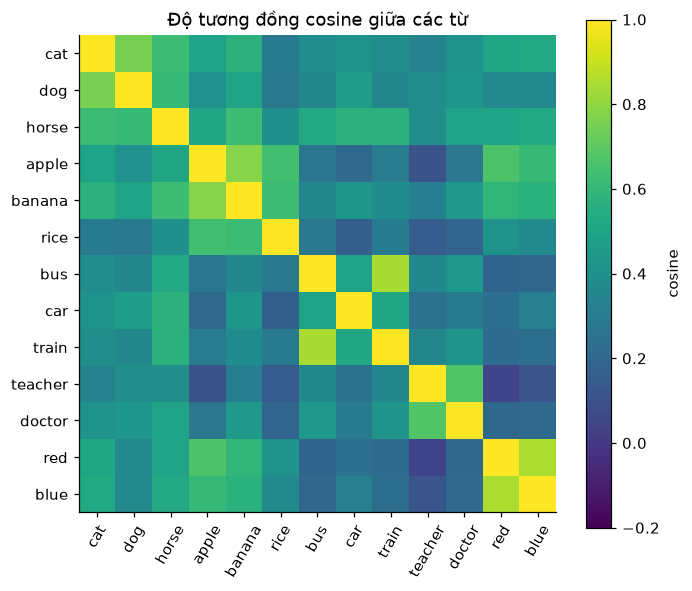

In [6]:
probe = ["cat", "dog", "horse", "apple", "banana", "rice", "bus", "car", "train", "teacher", "doctor", "red", "blue"]
probe = [w for w in probe if w in index]
m = unit[[index[w] for w in probe]] @ unit[[index[w] for w in probe]].T
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(m, cmap="viridis", vmin=-0.2, vmax=1)
ax.set_xticks(range(len(probe)), probe, rotation=60)
ax.set_yticks(range(len(probe)), probe)
ax.grid(False)
fig.colorbar(im, label="cosine")
ax.set_title("Độ tương đồng cosine giữa các từ")
save(fig, "04_w2v_cosine")
plt.show()

## 4.4 Khái niệm từ vựng chiếu xuống 2 chiều (PCA)
Các từ cùng chủ đề nằm gần nhau là dấu hiệu vector đã học được nghĩa.

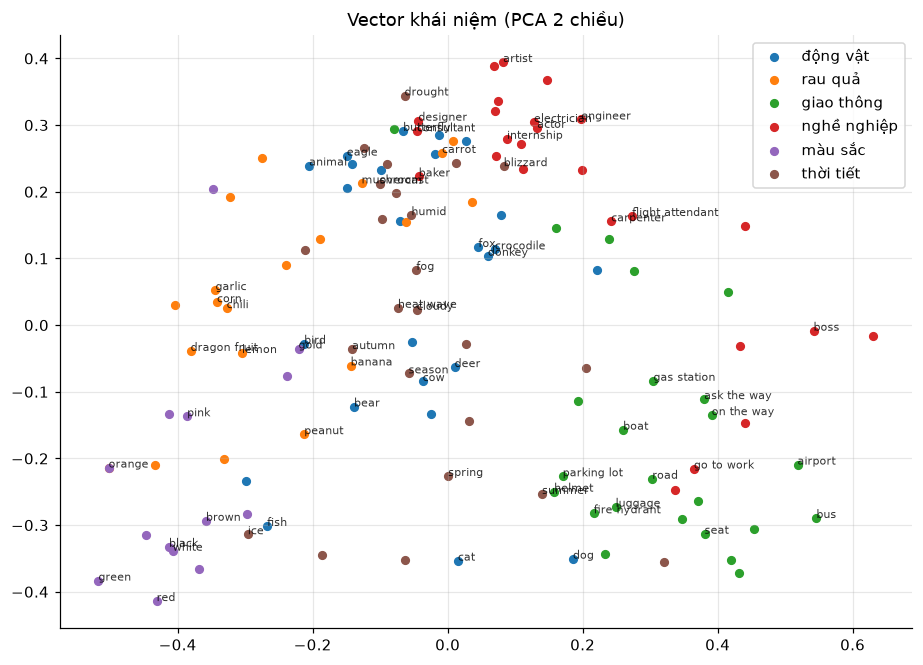

In [7]:
from apps.vocab.models import Word, WordTranslation

en = dict(WordTranslation.objects.filter(language_id="en").values_list("word_id", "text"))
topics = {"animals": "động vật", "fruits-vegetables": "rau quả", "transport": "giao thông", "jobs": "nghề nghiệp",
          "colors": "màu sắc", "weather": "thời tiết"}
pts, lab, txt = [], [], []
for slug, name in topics.items():
    for w in Word.objects.filter(topics__slug=slug)[:25]:
        v = word2vec.phrase_vector(en.get(w.id, w.slug), index, vecs)
        if v is not None:
            pts.append(v); lab.append(name); txt.append(en.get(w.id, w.slug))
X = np.array(pts) - np.mean(pts, axis=0)
xy = X @ np.linalg.svd(X, full_matrices=False)[2][:2].T
fig, ax = plt.subplots(figsize=(10, 7))
for name in topics.values():
    sel = [i for i, l in enumerate(lab) if l == name]
    ax.scatter(xy[sel, 0], xy[sel, 1], label=name, s=25)
for i in range(0, len(txt), 2):
    ax.annotate(txt[i], xy[i], fontsize=7, alpha=0.8)
ax.set_title("Vector khái niệm (PCA 2 chiều)")
ax.legend()
save(fig, "04_w2v_pca")
plt.show()

## 4.5 Lưu vector cho Smart Distractor (chỉ khi SAVE_VECTORS = True)

In [8]:
if SAVE_VECTORS:
    from apps.algorithms.distractor import VECTORS
    from apps.algorithms.models import ExperimentRun

    slugs, out = [], []
    for w in Word.objects.all():
        v = word2vec.phrase_vector(en.get(w.id, w.slug.replace("-", " ")), index, vecs)
        if v is not None:
            slugs.append(w.slug); out.append(v.astype(np.float32))
    np.savez_compressed(VECTORS, slugs=np.array(slugs), vectors=np.stack(out))
    probes = {q: [words[i] for i in np.argsort(-(unit @ unit[index[q]]))[1:7]]
              for q in ["cat", "apple", "teacher", "bus", "red", "happy", "rain", "doctor"] if q in index}
    ExperimentRun.objects.create(kind="word2vec", duration_s=duration, results={
        "sentences": len(corpus), "vocab": len(index), "dim": DIM, "epochs": EPOCHS, "concepts_with_vector": len(slugs),
        "concepts_total": Word.objects.count(), "neighbours": probes})
    print(f"Đã lưu {len(slugs)} vector → {VECTORS}")
else:
    print("Không ghi đè vector đang dùng (SAVE_VECTORS = False)")

Không ghi đè vector đang dùng (SAVE_VECTORS = False)
